In [1]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

# For this analysis, I used the National Longitudinal Survey of 1979 (NLSY97) dataset
nls = pd.read_csv("default.csv")
print(f"{nls.shape[0]:,} respondents x {nls.shape[1]} columns")
nls.head()

8,984 respondents x 86 columns


,R0000100,R0536300,R0536401,R0536402,R1235800,R1482600,U6225000,U6225100,U6225200,U6225300,...,U6924700,U6924800,U6924900,U6925000,U6925100,U6925200,U6925300,U6925400,U6925500,U6925600
0,1,2,9,1981,1,4,4470,-4,-4,-4,...,2,-4,-4,-4,-4,-4,-4,-4,-4,-4
1,2,1,7,1982,1,2,7680,-4,-4,-4,...,2,-4,-4,-4,-4,-4,-4,-4,-4,-4
2,3,2,9,1983,1,2,-5,-5,-5,-5,...,-5,-5,-5,-5,-5,-5,-5,-5,-5,-5
3,4,2,2,1981,1,2,9190,8770,-4,-4,...,1,2,-4,-4,-4,-4,-4,-4,-4,-4
4,5,1,10,1982,1,2,9470,770,-4,-4,...,1,1,-4,-4,-4,-4,-4,-4,-4,-4


In [2]:
# Person_Cols maps the NLSY97 variable names to more descriptive names for the person data (some were used from data descriptions)
PERSON_COLS = {
    "R0000100": "pubid",
    "R0536300": "sex",
    "R0536401": "birth_month",
    "R0536402": "birth_year",
    "R1235800": "sample_type",
    "R1482600": "race_ethnicity",
}

In [3]:
#JOB_GROUPS maps the NLSY97 variable names to more descriptive names for the job data
JOB_GROUPS = {
    "ind_code_2002":       62250,
    "occ_code_2002":       62260,
    "hrly_A_cents":        63570,
    "hrly_B_cents":        63580,
    "hours_per_week":      63590,
    "job_26wks_or_less":   63602,
    "weeks_worked_at_job": 63640,
    "jobsat_raw":          69247,
}

In [4]:
# Number of slots for the U variables
N_SLOTS = 10

def slot_col(start, i):
    return f"U{start + i}00"

In [5]:
# Check for missing columns in the data file
missing_cols = [slot_col(s, i) for s in JOB_GROUPS.values() for i in range(N_SLOTS)
                if slot_col(s, i) not in nls.columns]
unused_cols = set(nls.columns) - set(PERSON_COLS) - {slot_col(s, i) for s in JOB_GROUPS.values() for i in range(N_SLOTS)}
print("Expected columns missing from file:", missing_cols)
print("Columns in file not in dictionary:", sorted(unused_cols))

Expected columns missing from file: []
Columns in file not in dictionary: []


In [6]:
MISSING_CODES = {-1: "Refusal", -2: "Don't know", -3: "Invalid skip",-4: "Valid skip", -5: "Non-interview"}

# Display the counts of missing codes
code_counts = pd.DataFrame({
    "code": list(MISSING_CODES),
    "label": list(MISSING_CODES.values()),
    "cells": [int((nls == c).sum().sum()) for c in MISSING_CODES],
})
display(code_counts)

# Display people that were interviewed and not interviewed in 2023
sat1 = nls[slot_col(JOB_GROUPS["jobsat_raw"], 0)]
print("Respondents not interviewed in 2023:", int((sat1 == -5).sum()))
print("Respondents interviewed in 2023:    ", int((sat1 != -5).sum()))

raw = nls.copy()
nls = nls.replace(list(MISSING_CODES), np.nan)
nls.isna().mean().sort_values(ascending=False).head(8).round(3)


,code,label,cells
0,-1,Refusal,12
1,-2,Don't know,5
2,-3,Invalid skip,1221
3,-4,Valid skip,457404
4,-5,Non-interview,193200


Respondents not interviewed in 2023: 2415
Respondents interviewed in 2023:     6569


U6225900    1.0
U6364900    1.0
U6925400    1.0
U6358900    1.0
U6357900    1.0
U6226900    1.0
U6359900    1.0
U6361100    1.0
dtype: float64

In [7]:
# Created DataFrame with one row per person
parts = []
for i in range(N_SLOTS):
    p = nls[list(PERSON_COLS)].rename(columns=PERSON_COLS).copy()
    p["employer_slot"] = i + 1
    for name, start in JOB_GROUPS.items():
        p[name] = nls[slot_col(start, i)]
    parts.append(p)

jobs_all = pd.concat(parts, ignore_index=True)
print("All person-slot rows:", f"{len(jobs_all):,}")

All person-slot rows: 89,840


In [8]:
# Dropped rows with no job information 
job_info = ["occ_code_2002", "ind_code_2002", "hours_per_week", "weeks_worked_at_job", "jobsat_raw"]
jobs_any = jobs_all.dropna(subset=job_info, how="all")
print("Rows with any job information:", f"{len(jobs_any):,}")

df = jobs_all.dropna(subset=["jobsat_raw"]).copy()
print("Jobs with a satisfaction answer:", f"{len(df):,}", "from", f"{df['pubid'].nunique():,}", "people")
print("Duplicate (person, slot) rows:", df.duplicated(["pubid", "employer_slot"]).sum())

slot_summary = (df.groupby("employer_slot")
                  .agg(jobs=("pubid", "size"))
                  .reset_index())
display(slot_summary.T)

Rows with any job information: 8,792
Jobs with a satisfaction answer: 7,680 from 5,713 people
Duplicate (person, slot) rows: 0


,0,1,2,3,4,5,6,7,8,9
employer_slot,1,2,3,4,5,6,7,8,9,10
jobs,5336,1710,445,125,40,14,6,1,2,1


,job_satisfaction,jobs,pct,original_label
0,1.0,251,3.3,Dislike it very much
1,2.0,292,3.8,Dislike it somewhat
2,3.0,1612,21.0,Think it is OK
3,4.0,2285,29.8,Like it fairly well
4,5.0,3240,42.2,Like it very much


Mean: 4.04
Median: 4.0


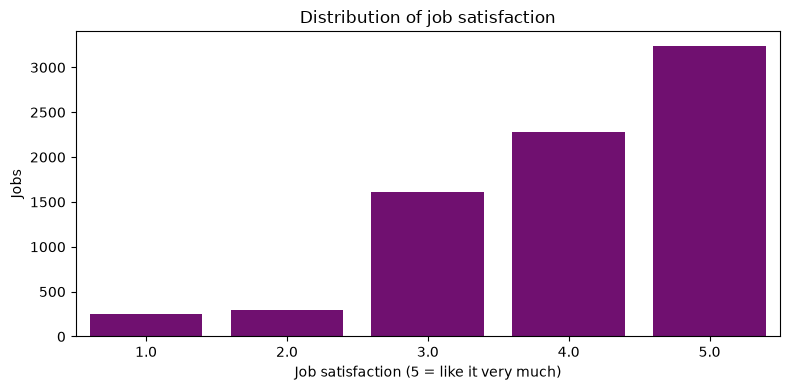

,satisfied_if_score_at_least,satisfied_n,not_satisfied_n,satisfied_pct
0,3,7137,543,92.9
1,4,5525,2155,71.9
2,5,3240,4440,42.2


In [9]:
# Job satisfaction labels
SAT_LABELS = {1: "Like it very much", 2: "Like it fairly well", 3: "Think it is OK",
              4: "Dislike it somewhat", 5: "Dislike it very much"}

# 5 = likes it greatly
# 1 = dislikes it greatly

df["job_satisfaction"] = 6 - df["jobsat_raw"]

dist = (df["job_satisfaction"].value_counts().sort_index()
          .rename_axis("job_satisfaction").reset_index(name="jobs"))
dist["pct"] = (100 * dist["jobs"] / dist["jobs"].sum()).round(1)
dist["original_label"] = (6 - dist["job_satisfaction"]).map(SAT_LABELS)
display(dist)

print("Mean:", round(df["job_satisfaction"].mean(), 2))
print("Median:", df["job_satisfaction"].median())

# Bar Plot
plt.figure(figsize=(8, 4))
sns.countplot(x=df["job_satisfaction"], color="purple")
plt.xlabel("Job satisfaction (5 = like it very much)")
plt.ylabel("Jobs")
plt.title("Distribution of job satisfaction")
plt.tight_layout()
plt.show()

thresholds = []
for cutoff in [3, 4, 5]:
    s = df["job_satisfaction"]
    thresholds.append({
        "satisfied_if_score_at_least": cutoff,
        "satisfied_n": int((s >= cutoff).sum()),
        "not_satisfied_n": int((s < cutoff).sum()),
        "satisfied_pct": round(100 * (s >= cutoff).mean(), 1),
    })
display(pd.DataFrame(thresholds))

SAT_CUTOFF = 4        # This value can be changed to test other definitions
df["satisfied"] = (df["job_satisfaction"] >= SAT_CUTOFF).astype(int)

,variable,missing_n,missing_pct
2,hrly_A_cents,567,7.4
3,hrly_B_cents,357,4.6
0,ind_code_2002,342,4.5
6,weeks_worked_at_job,320,4.2
1,occ_code_2002,214,2.8
4,hours_per_week,145,1.9
5,job_26wks_or_less,85,1.1


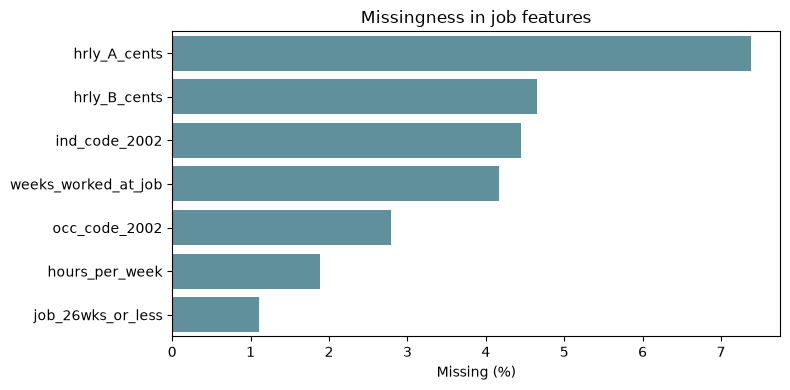

In [10]:
feature_cols = ["ind_code_2002", "occ_code_2002", "hrly_A_cents", "hrly_B_cents",
                "hours_per_week", "job_26wks_or_less", "weeks_worked_at_job"]

# Created a DataFrame for missingness in jobs 
missing = pd.DataFrame({
    "variable": feature_cols,
    "missing_n": [df[c].isna().sum() for c in feature_cols],
    "missing_pct": [100 * df[c].isna().mean() for c in feature_cols],
}).sort_values("missing_pct", ascending=False)
display(missing.round(1))

# Bar Plot
plt.figure(figsize=(8, 4))
sns.barplot(data=missing, x="missing_pct", y="variable", color="#5596a5")
plt.xlabel("Missing (%)")
plt.ylabel("")
plt.title("Missingness in job features")
plt.tight_layout()
plt.show()

,hrly_A_dollars,hrly_B_dollars,hours_per_week,tenure_years
count,7113.00,7323.00,7535.00,7360.00
mean,40.17,35.84,36.96,6.31
std,45.05,37.39,14.61,5.67
min,0.00,0.00,0.00,0.02
1%,0.00,0.00,0.00,0.54
25%,19.15,18.00,35.00,1.83
50%,27.50,25.00,40.00,4.25
75%,43.82,40.00,40.00,9.25
99%,294.77,249.98,72.00,22.68
max,294.77,249.98,168.00,31.58


Hourly pay = 0:        72
Hourly pay A at its maximum ($294.77): 160 | rows between $150 and the maximum: 0
Hours per week = 0:    95
Hours per week > 80:   33


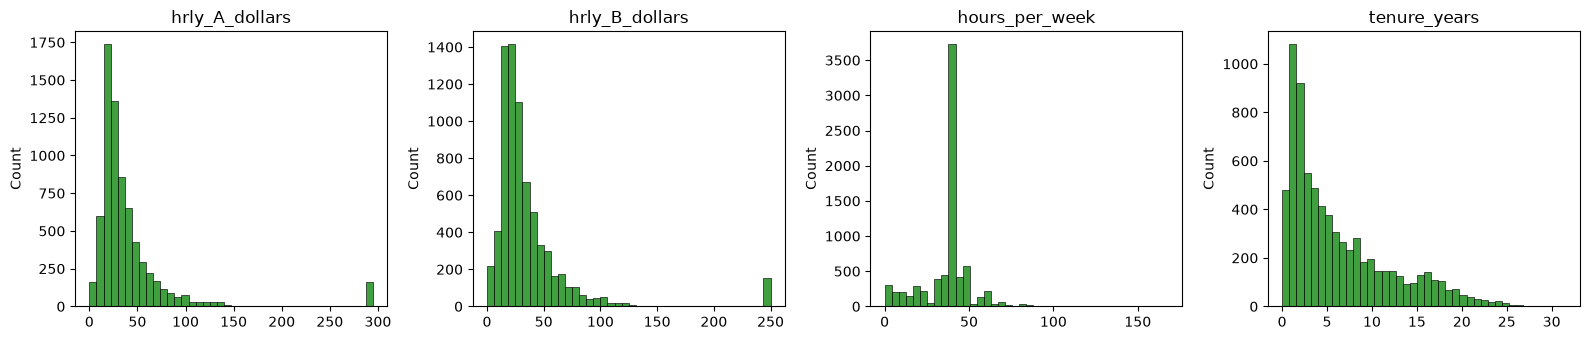

,hrly_A_wins,hrly_B_wins,hours_wins,tenure_years_wins
count,7041.00,7208.00,7440.00,7360.00
mean,40.61,36.44,37.25,6.30
std,45.07,37.39,13.28,5.61
min,6.36,4.74,2.00,0.54
25%,19.43,18.00,35.00,1.83
50%,27.78,25.64,40.00,4.25
75%,44.10,40.63,40.00,9.25
max,294.77,249.98,72.00,22.68


In [11]:
# Divided hourly pay by 100 to convert cents to dollars
# Divided weeks worked by 52 to convert to years

df["hrly_A_dollars"] = df["hrly_A_cents"] / 100
df["hrly_B_dollars"] = df["hrly_B_cents"] / 100
df["tenure_years"] = df["weeks_worked_at_job"] / 52

num_cols = ["hrly_A_dollars", "hrly_B_dollars", "hours_per_week", "tenure_years"]
display(df[num_cols].describe(percentiles=[.01, .25, .5, .75, .99]).round(2))

print("Hourly pay = 0:       ", int((df["hrly_A_dollars"] == 0).sum()))
top_A = df["hrly_A_dollars"].max()
print(f"Hourly pay A at its maximum (${top_A:,.2f}):", int((df["hrly_A_dollars"] == top_A).sum()),
      "| rows between $150 and the maximum:", int(df["hrly_A_dollars"].between(150, top_A, inclusive="neither").sum()))
print("Hours per week = 0:   ", int((df["hours_per_week"] == 0).sum()))
print("Hours per week > 80:  ", int((df["hours_per_week"] > 80).sum()))

# Histograms of numeric features
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col].dropna(), bins=40, color="green", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

df["flag_zero_pay"] = (df["hrly_A_dollars"] == 0).astype(int)
df["flag_pay_topcoded"] = ((df["hrly_A_dollars"] == df["hrly_A_dollars"].max()) |
                           (df["hrly_B_dollars"] == df["hrly_B_dollars"].max())).astype(int)
df["flag_hours_over_80"] = (df["hours_per_week"] > 80).astype(int)

#Limits extreme values in a series (1st and 99th percentiles)
def winsorize(s, lo=0.01, hi=0.99):
    lo_v, hi_v = s.quantile([lo, hi])
    return s.clip(lo_v, hi_v)

df["hrly_A_wins"] = winsorize(df["hrly_A_dollars"].where(df["hrly_A_dollars"] > 0))
df["hrly_B_wins"] = winsorize(df["hrly_B_dollars"].where(df["hrly_B_dollars"] > 0))
df["hours_wins"] = winsorize(df["hours_per_week"].where(df["hours_per_week"] > 0))
df["tenure_years_wins"] = winsorize(df["tenure_years"])

df[["hrly_A_wins", "hrly_B_wins", "hours_wins", "tenure_years_wins"]].describe().round(2)

In [12]:
df["sex_label"] = df["sex"].map({1: "Male", 2: "Female"})
df["race_label"] = df["race_ethnicity"].map({1: "Black", 2: "Hispanic", 3: "Mixed (non-Hispanic)", 4: "Non-Black / Non-Hispanic"})
df["sample_label"] = df["sample_type"].map({1: "Cross-sectional", 0: "Oversample"})
df["age_2023"] = 2023 - df["birth_year"]

# Display the amount of people for each category
for col in ["sex_label", "race_label", "sample_label"]:
    display(df.drop_duplicates("pubid")[col].value_counts(dropna=False).rename_axis(col).to_frame("people"))

print(df.drop_duplicates("pubid")["age_2023"].describe().round(1))

,people
sex_label,
Male,2875
Female,2838


,people
race_label,
Non-Black / Non-Hispanic,2935
Black,1511
Hispanic,1212
Mixed (non-Hispanic),55


,people
sample_label,
Cross-sectional,4282
Oversample,1431


count    5713.0
mean       41.0
std         1.4
min        39.0
25%        40.0
50%        41.0
75%        42.0
max        43.0
Name: age_2023, dtype: float64


In [13]:
# Occupation groups
OCC_RANGES = [
    (10, 430, "Management"),
    (500, 950, "Business and financial operations"),
    (1000, 1240, "Computer and mathematical"),
    (1300, 1560, "Architecture and engineering"),
    (1600, 1980, "Life, physical, and social science"),
    (2000, 2060, "Community and social service"),
    (2100, 2150, "Legal"),
    (2200, 2550, "Educational instruction and library"),
    (2600, 2920, "Arts, design, entertainment, sports, and media"),
    (3000, 3540, "Healthcare practitioners and technical"),
    (3600, 3650, "Healthcare support"),
    (3700, 3950, "Protective service"),
    (4000, 4160, "Food preparation and service"),
    (4200, 4250, "Building and grounds cleaning and maintenance"),
    (4300, 4650, "Personal care and service"),
    (4700, 4960, "Sales and related"),
    (5000, 5930, "Office and administrative support"),
    (6000, 6130, "Farming, fishing, and forestry"),
    (6200, 6940, "Construction and extraction"),
    (7000, 7620, "Installation, maintenance, and repair"),
    (7700, 8960, "Production"),
    (9000, 9750, "Transportation and material moving"),
    (9800, 9840, "Military"),
]

In [14]:
# Used a function to categorize occupation codes into groups
def occ_group(code):
    if pd.isna(code):
        return np.nan
    for lo, hi, name in OCC_RANGES:
        if lo <= code <= hi:
            return name
    return "Unmapped / other"

df["occupation_group"] = df["occ_code_2002"].apply(occ_group)

print("Jobs with an occupation code:", int(df["occ_code_2002"].notna().sum()))
print("Unmapped codes:", df.loc[df["occupation_group"] == "Unmapped / other", "occ_code_2002"].value_counts().to_dict())

occ_summary = (df.dropna(subset=["occupation_group"])
                 .groupby("occupation_group")
                 .agg(jobs=("pubid", "size"),
                      mean_satisfaction=("job_satisfaction", "mean"),
                      pct_satisfied=("satisfied", "mean"))
                 .sort_values("jobs", ascending=False)
                 .reset_index())
occ_summary["pct_satisfied"] = (100 * occ_summary["pct_satisfied"]).round(1)
display(occ_summary.round(2))

Jobs with an occupation code: 7466
Unmapped codes: {9990.0: 24}


,occupation_group,jobs,mean_satisfaction,pct_satisfied
0,Management,1022,4.23,79.1
1,Office and administrative support,957,3.92,67.6
2,Sales and related,639,3.96,69.0
3,Transportation and material moving,519,3.84,61.5
4,Educational instruction and library,445,4.20,81.6
5,Healthcare practitioners and technical,442,3.98,71.5
6,Business and financial operations,413,4.11,75.1
7,Production,364,3.78,62.6
8,Construction and extraction,332,4.17,76.5
9,Food preparation and service,325,3.76,58.8


,feature,available_n,spearman_with_satisfaction
0,hrly_A_wins,7041,0.140
1,hrly_B_wins,7208,0.141
2,hours_wins,7440,-0.002
3,tenure_years_wins,7360,0.075
4,age_2023,7680,0.030


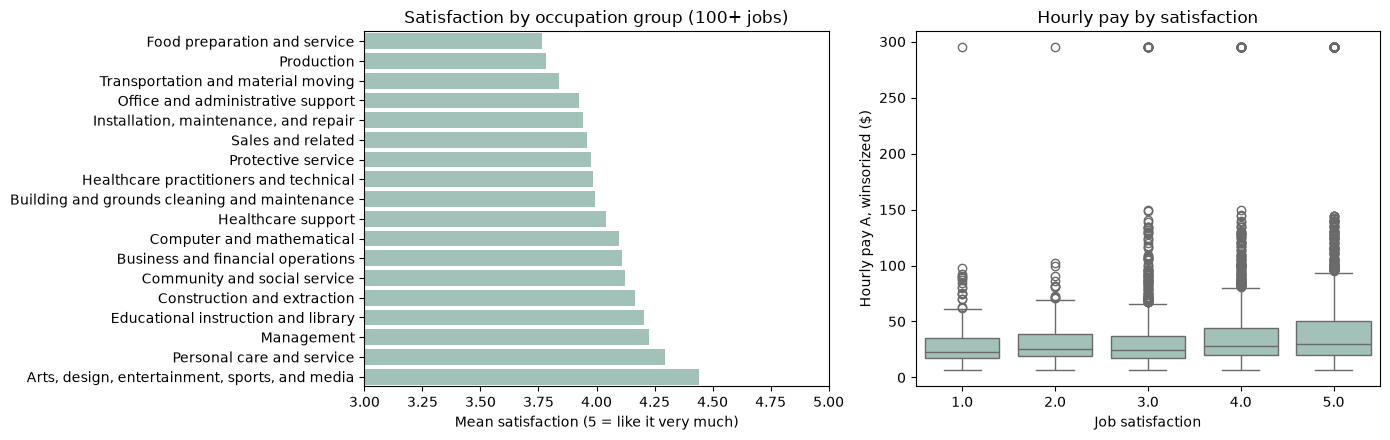

,count,mean
sex_label,,
Female,3883,4.05
Male,3797,4.03


,count,mean
race_label,,
Black,2053,3.90
Hispanic,1587,4.14
Mixed (non-Hispanic),81,4.05
Non-Black / Non-Hispanic,3959,4.07


In [15]:
corr_cols = ["hrly_A_wins", "hrly_B_wins", "hours_wins", "tenure_years_wins", "age_2023"]
rows = []
for col in corr_cols:
    sub = df[["job_satisfaction", col]].dropna()
    rows.append({"feature": col, "available_n": len(sub),
                 "spearman_with_satisfaction": sub["job_satisfaction"].corr(sub[col], method="spearman")})
display(pd.DataFrame(rows).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

#Bar Plot of mean satisfaction by occupation group
big = occ_summary[occ_summary["jobs"] >= 100].sort_values("mean_satisfaction")
sns.barplot(data=big, x="mean_satisfaction", y="occupation_group", color="#9dc6ba", ax=axes[0])
axes[0].set_xlabel("Mean satisfaction (5 = like it very much)")
axes[0].set_ylabel("")
axes[0].set_title("Satisfaction by occupation group (100+ jobs)")
axes[0].set_xlim(3, 5)

#Box Plot of hourly pay by satisfaction
sns.boxplot(data=df, x="job_satisfaction", y="hrly_A_wins", color="#9dc6ba", ax=axes[1])
axes[1].set_xlabel("Job satisfaction")
axes[1].set_ylabel("Hourly pay A, winsorized ($)")
axes[1].set_title("Hourly pay by satisfaction")

plt.tight_layout()
plt.show()

by_sex = df.groupby("sex_label")["job_satisfaction"].agg(["count", "mean"]).round(2)
by_race = df.groupby("race_label")["job_satisfaction"].agg(["count", "mean"]).round(2)
display(by_sex)
display(by_race)


In [16]:
# Kept only the columns needed for analysis and saved into nlsy87_clean.csv
keep = ["pubid", "employer_slot", "sex_label", "race_label", "sample_label", "age_2023",
        "occ_code_2002", "ind_code_2002", "occupation_group",
        "hrly_A_dollars", "hrly_B_dollars", "hrly_A_wins", "hrly_B_wins",
        "hours_per_week", "hours_wins", "tenure_years", "tenure_years_wins",
        "job_26wks_or_less", "flag_zero_pay", "flag_pay_topcoded", "flag_hours_over_80",
        "jobsat_raw", "job_satisfaction", "satisfied"]
clean = df[keep].sort_values(["pubid", "employer_slot"]).reset_index(drop=True)

assert not clean.duplicated(["pubid", "employer_slot"]).any()
assert clean["job_satisfaction"].between(1, 5).all()

clean.to_csv("nlsy97_clean.csv", index=False)
print("Saved", clean.shape)
clean.head()

Saved (7680, 24)


,pubid,employer_slot,sex_label,race_label,sample_label,age_2023,occ_code_2002,ind_code_2002,occupation_group,hrly_A_dollars,...,hours_wins,tenure_years,tenure_years_wins,job_26wks_or_less,flag_zero_pay,flag_pay_topcoded,flag_hours_over_80,jobsat_raw,job_satisfaction,satisfied
0,1,1,Female,Non-Black / Non-Hispanic,Cross-sectional,42,800.0,4470.0,Business and financial operations,20.00,...,40.0,9.269231,9.269231,0.0,0,0,0,2.0,4.0,1
1,2,1,Male,Hispanic,Cross-sectional,41,3820.0,7680.0,Protective service,55.30,...,40.0,16.403846,16.403846,0.0,0,0,0,2.0,4.0,1
2,4,1,Female,Hispanic,Cross-sectional,42,5700.0,9190.0,Office and administrative support,47.00,...,40.0,0.673077,0.673077,0.0,0,0,0,1.0,5.0,1
3,4,2,Female,Hispanic,Cross-sectional,42,5700.0,8770.0,Office and administrative support,18.27,...,52.0,5.326923,5.326923,0.0,0,0,0,2.0,4.0,1
4,5,1,Male,Hispanic,Cross-sectional,41,3740.0,9470.0,Protective service,44.11,...,48.0,17.461538,17.461538,0.0,0,0,0,1.0,5.0,1
